# Vòng siêu tham số nâng cao

Mở từ thư mục dự án với kernel của môi trường dự án. Các ô đọc config, bảng và hình đã công bố.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "reports/stage5_inputs.json").is_file())
sys.path.insert(0, str(root))
from src.wrmsse_stage5 import STAGE2, STAGE3, STAGE4, SELECTED, TABLES, csv, read, check_gates
check_gates()

def table(name):
    return csv(TABLES / (name + ".csv"))

def figure(number):
    path, = (root / "reports/figures").glob(f"{number:02d}_*.png")
    display(Image(filename=str(path), width=950))


RF-06–RF-22 dùng bộ cơ sở RF-v1. RF-15 có WRMSSE thấp nhất trong vòng nâng cao. So sánh thời gian dựa trên tài nguyên ghi nhận của lượt fit nguồn. Các lượt dùng 4 hoặc 8 luồng, và bảng ghi trường hợp reuse.

,experiment,validation_wrmsse,fit_seconds,n_jobs,reuse
24,RF-21,0.664771,252.654004,8,True
18,RF-15,0.664771,252.654004,8,False
20,RF-17,0.672596,169.077171,8,False
23,RF-20,0.679221,281.083941,8,False
17,RF-14,0.683358,259.724504,4,False
21,RF-18,0.685534,202.624195,8,False
25,RF-22,0.689104,151.032034,8,False
11,RF-08,0.698311,293.641195,4,False
16,RF-13,0.698979,157.985567,4,False
10,RF-07,0.706405,199.260174,4,False


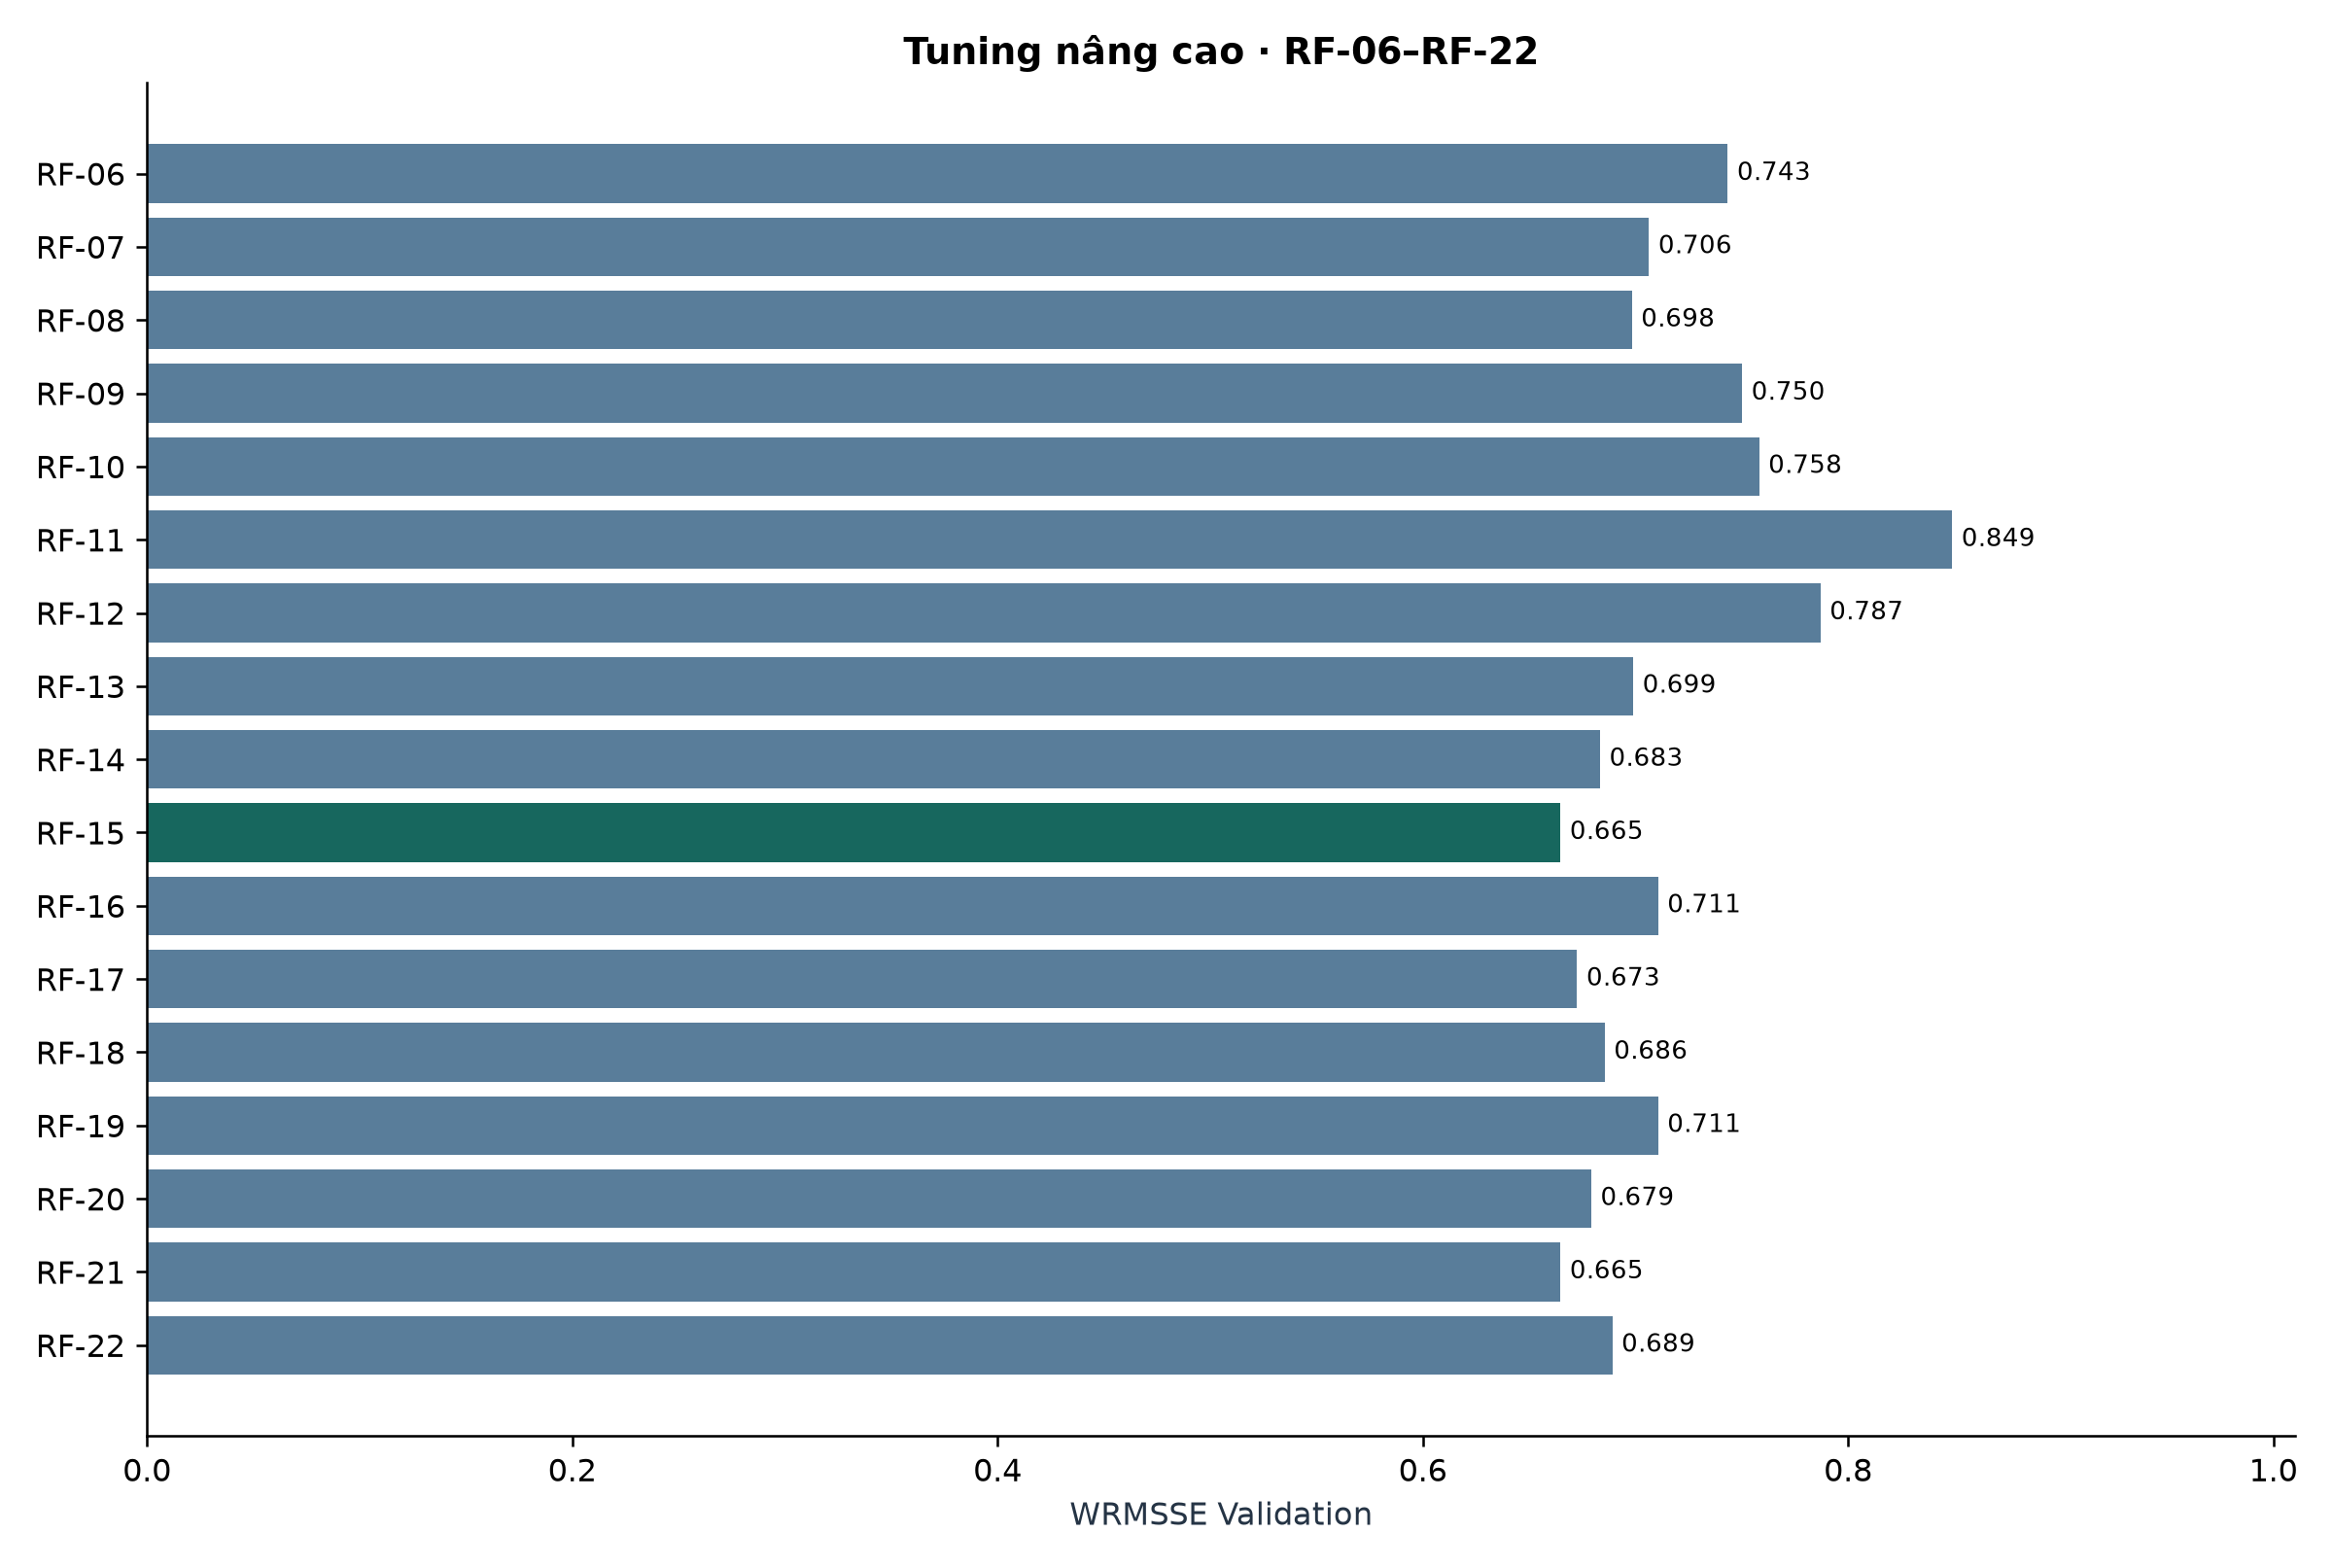

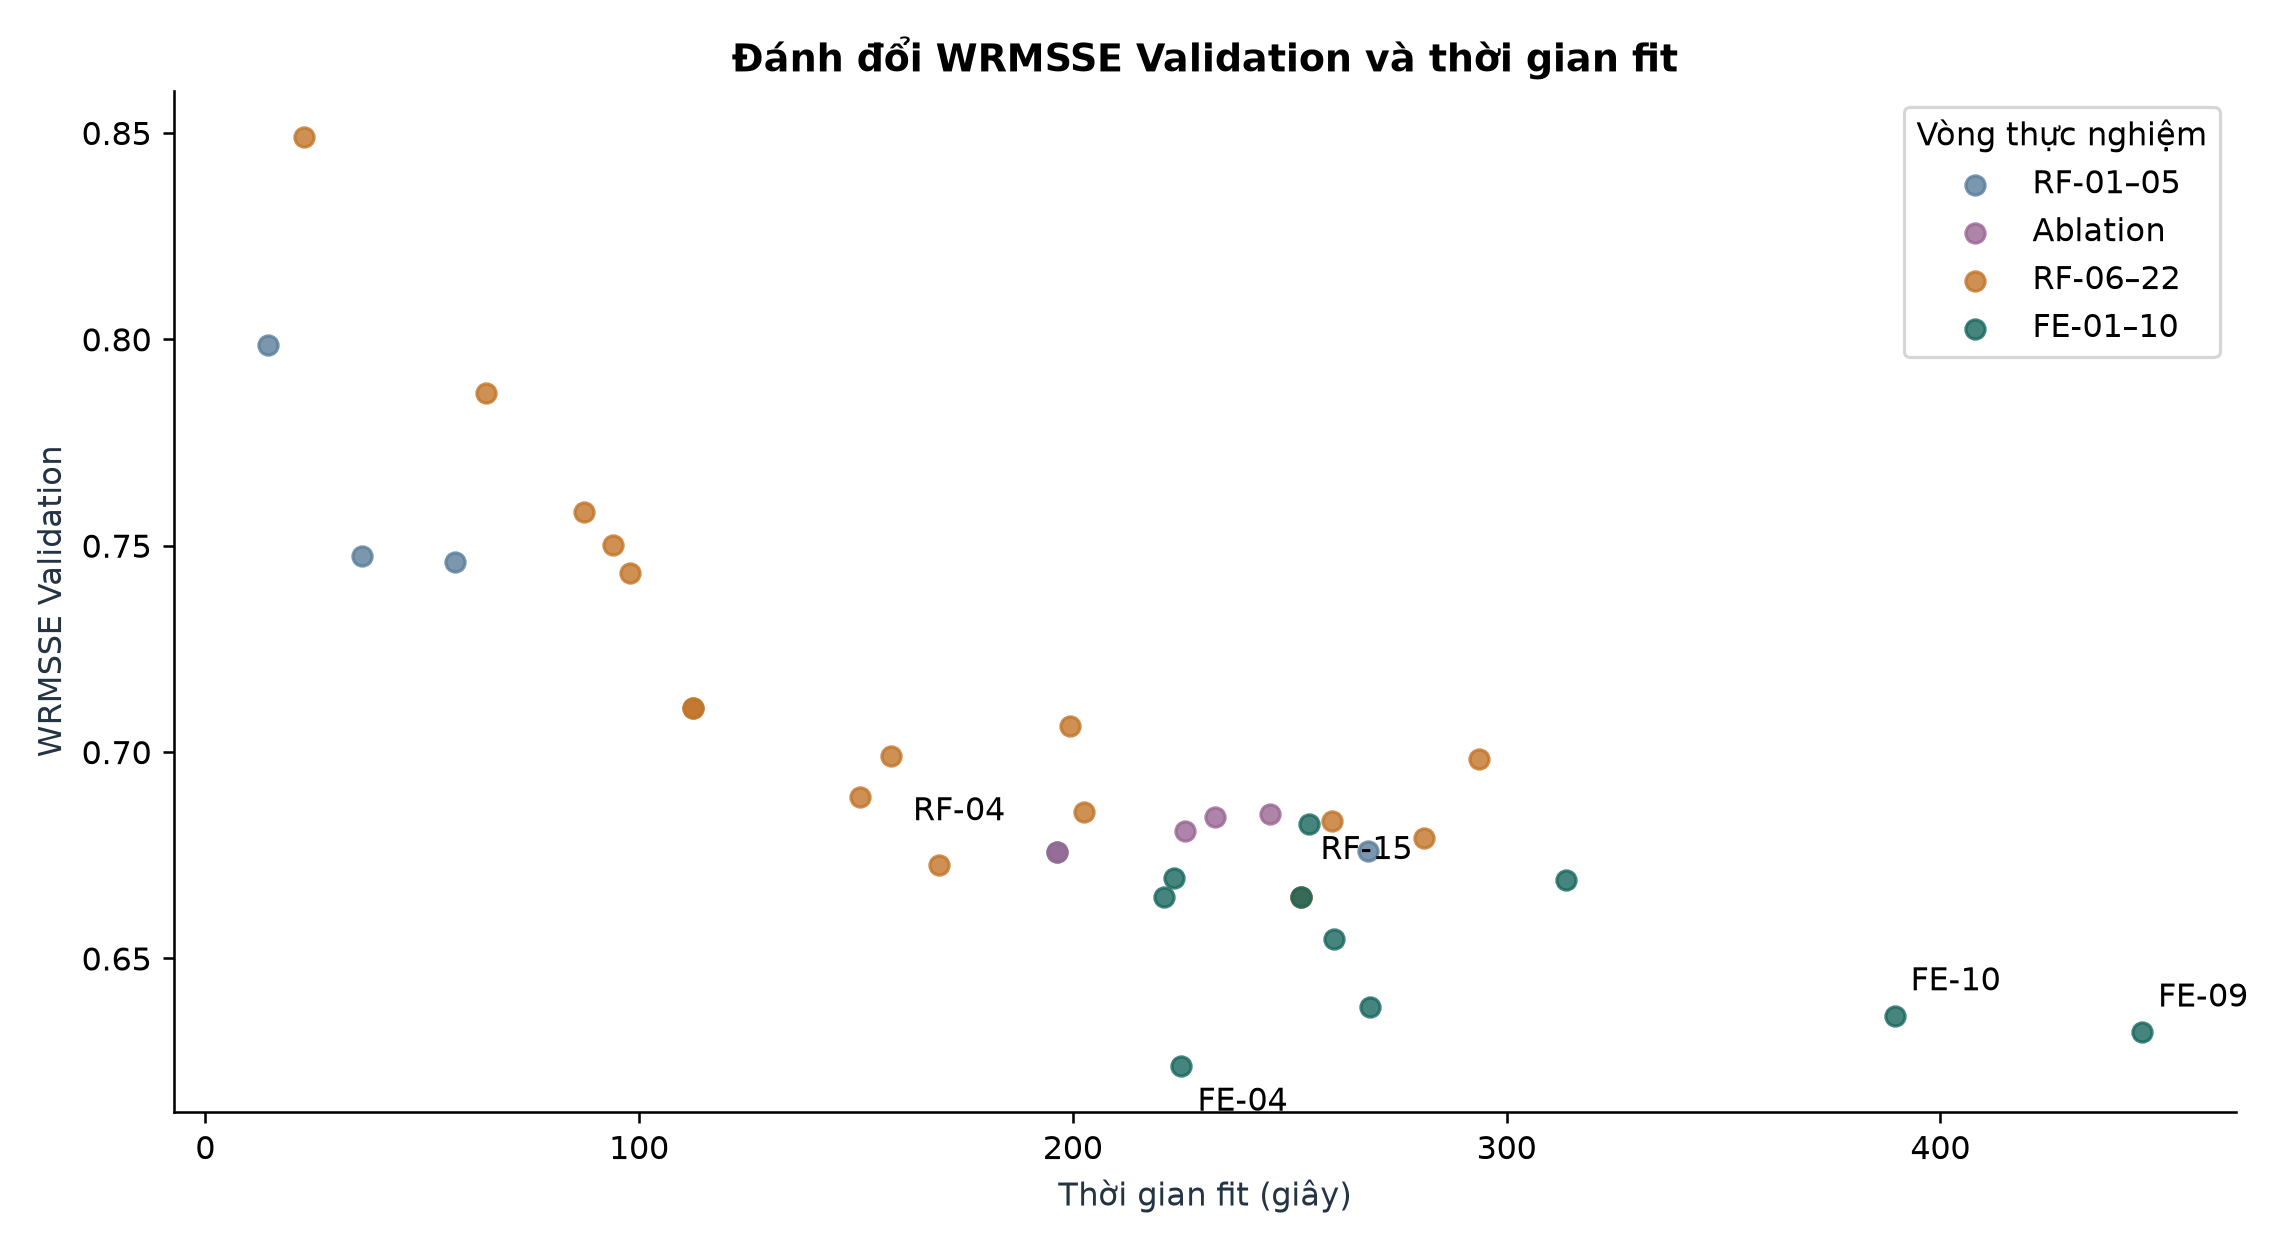

In [2]:
advanced = table("experiment_results").query("group == 'advanced'").sort_values("validation_wrmsse")
display(advanced[["experiment", "validation_wrmsse", "fit_seconds", "n_jobs", "reuse"]])
figure(5)
figure(8)